# Day 3-04 | Mini Project: Track IDs, BEV Paths and Team Clustering

[Open in Colab](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day3/d3_04_tracking_to_bev_mini_project_en.ipynb)

[English](d3_04_tracking_to_bev_mini_project_en.ipynb) | [Japanese](d3_04_tracking_to_bev_mini_project_ja.ipynb) | [Traditional Chinese](d3_04_tracking_to_bev_mini_project.ipynb)


> Combine the first three days: YOLO detects players, ByteTrack maintains IDs, court keypoints estimate homography, and footpoints map to BEV coordinates.  
> Each resulting row answers: **which track, in which frame, at which court position?**

## Learning Objectives

- Export side-by-side camera/BEV tracking video.
- Follow the data flow `track_id -> bbox -> footpoint -> bev_xy`.
- Collect torso crops for each `track_id` and cluster mean HSV features into Team A/B.
- Draw team labels on the original frame and team-colored paths on BEV.
- Export frame-level data and team assignments as CSV/JSON.
- Distinguish temporary homography failure from tracking identity failure.


## Prerequisites for This Exercise

- Day 1: homography maps camera coordinates to BEV coordinates.
- Day 2: a player's box bottom-center approximates the footpoint.
- Day 3-02: ByteTrack maintains `track_id` for a target across adjacent frames.
- Day 3-03: torso crops, HSV histograms and two-cluster K-means provide team features.

This notebook focuses on integrating tracking, BEV and track-level team clustering, without repeating manual IoU or single-frame clustering.


## Workflow

1. Set the video, player detector, court-keypoint model and BEV specification.
2. Run the tracking-to-BEV pipeline and inspect the side-by-side video.
3. Trace one row through `bbox_xyxy -> foot_x/foot_y -> bev_x/bev_y`.
4. Export CSV and summarize each `track_id`'s observed range and mean position.
5. Collect torso crops across frames for stable track-level team features.
6. Draw representative team boxes, the HSV feature distribution and team-colored BEV paths.
7. Export browser-playable team tracking video.
8. Record ID switches, missed detections, insufficient court keypoints, projection jitter and team errors.


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "en"

# Prepare the course environment and display a short confirmation.
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
import subprocess
import sys

from IPython.display import Markdown, display

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("This Colab runtime cannot mount Drive; using local /content storage.")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

with redirect_stdout(StringIO()):
    COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)
display(Markdown(
    f"✅ **Course environment ready**  \n"
    f"Project root: `{COURSE_ROOT}`"
))


✅ **Course environment ready**  
Project root: `/Users/henry753951/Developer/sandbox/basketball-hackathon-course`

## Step 1 | Set the Four Pipeline Inputs

- Game video: supplies each frame.
- Player detector: outputs player boxes.
- Court-keypoint model: outputs fixed court points for estimating homography.
- BEV specification: defines the court diagram's dimensions and line locations.


In [2]:
# Set video, model and output options; summarize the experiment inputs in a table.
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from contextlib import redirect_stdout
from io import StringIO
from IPython.display import Markdown, display

from src.video_utils import (
    display_video_in_notebook,
    ensure_notebook_playable_mp4,
)
from src.yolo_utils import (
    detector_model_path,
    preferred_court_keypoint_model_path,
    reference_videos,
    write_bytetrack_bev_video,
)

videos = reference_videos(COURSE_ROOT)
if len(videos) < 3:
    raise FileNotFoundError("At least three reference videos are required in assets/raw/reference_videos/.")

VIDEO_PATH = videos[2]
DETECTOR_PATH = detector_model_path(COURSE_ROOT)
COURT_MODEL_PATH = preferred_court_keypoint_model_path(COURSE_ROOT)
BEV_SPEC_PATH = COURSE_ROOT / "assets" / "samples" / "sample_bev_court.json"
OUTPUT_PATH = COURSE_ROOT / "assets" / "results" / "d3_04_bytetrack_bev.mp4"
OUT_CSV = COURSE_ROOT / "assets" / "results" / "d3_04_bytetrack_bev.csv"
START_FRAME = 30
MAX_FRAMES = 45

def readable_number(value: object, digits: int = 1) -> str:
    # Use consistent decimal precision for readable tables.
    return f"{float(str(value)):.{digits}f}"

def readable_bbox(value: object) -> str:
    # Format [x1, y1, x2, y2] as a short readable string.
    if not isinstance(value, (list, tuple)) or len(value) != 4:
        return str(value)
    return "(" + ", ".join(readable_number(item) for item in value) + ")"

input_overview = pd.DataFrame([
    {"Item": "Game video", "Selected": VIDEO_PATH.name, "Purpose": "Supply frame images"},
    {"Item": "Player detector", "Selected": DETECTOR_PATH.name, "Purpose": "Detect player boxes"},
    {"Item": "Court keypoint model", "Selected": COURT_MODEL_PATH.name, "Purpose": "Estimate homography"},
    {"Item": "BEV specification", "Selected": BEV_SPEC_PATH.name, "Purpose": "Define court-diagram coordinates"},
    {"Item": "Processing range", "Selected": f"{MAX_FRAMES} frames from frame {START_FRAME}", "Purpose": "Bound demo runtime"},
    {"Item": "Output video", "Selected": OUTPUT_PATH.name, "Purpose": "Save tracking-to-BEV results"},
])

display(Markdown("### Check Before Running\nThe table lists pipeline inputs and scope. Change the uppercase variables above to select another video or process more frames."))
display(input_overview.set_index("Item"))


### Check Before Running
The table lists pipeline inputs and scope. Change the uppercase variables above to select another video or process more frames.

,Selected,Purpose
Item,,
Game video,boston-celtics-new-york-knicks-game-1-q1-04.28...,Supply frame images
Player detector,yolo26n_basketball_player_best.pt,Detect player boxes
Court keypoint model,yolo26n_basketball_court_pose_best.pt,Estimate homography
BEV specification,sample_bev_court.json,Define court-diagram coordinates
Processing range,45 frames from frame 30,Bound demo runtime
Output video,d3_04_bytetrack_bev.mp4,Save tracking-to-BEV results


## Step 2 | Run `detection -> tracking -> footpoint -> Homography`

`write_bytetrack_bev_video()` performs:

```text
frame
  -> player BBOX
  -> ByteTrack track_id
  -> BBOX bottom-center footpoint
  -> court keypoints -> Homography
  -> BEV coordinate
```

If a frame lacks sufficient court keypoints, the code temporarily reuses the last reliable homography. This reduces flicker but cannot recover long periods without visible court lines.


In [3]:
# Run tracking-to-BEV, inspect the summary, then watch the video.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    with redirect_stdout(StringIO()):
        bev_video, records = write_bytetrack_bev_video(
            video_path=VIDEO_PATH,
            detector_path=DETECTOR_PATH,
            court_model_path=COURT_MODEL_PATH,
            bev_spec_path=BEV_SPEC_PATH,
            output_path=OUTPUT_PATH,
            max_frames=MAX_FRAMES,
            detector_conf=0.25,
            keypoint_conf=0.15,
            anchor_confidence=0.25,
            imgsz=960,
            start_frame=START_FRAME,
        )

record_frame = pd.DataFrame(records)
processed_frame_count = record_frame["frame"].nunique() if not record_frame.empty else 0
tracked_id_count = record_frame["track_id"].nunique() if not record_frame.empty else 0
pipeline_overview = pd.DataFrame([
    {"Check": "Processed frames", "Result": processed_frame_count, "Interpretation": "Distinct frames with generated data"},
    {"Check": "Frame-level player records", "Result": len(records), "Interpretation": "One row is one Track ID observation in one frame"},
    {"Check": "Distinct Track IDs", "Result": tracked_id_count, "Interpretation": "Not the actual player count; ID switches can increase it"},
    {"Check": "Preview video", "Result": bev_video.name, "Interpretation": "Camera view on the left, BEV on the right"},
])

display(Markdown("### Pipeline Summary\nCheck that the data volume is reasonable, then inspect ID and BEV stability in the video."))
display(pipeline_overview.set_index("Check"))
display_video_in_notebook(bev_video, loop=True)


### Pipeline Summary
Check that the data volume is reasonable, then inspect ID and BEV stability in the video.

,Result,Interpretation
Check,,
Processed frames,45,Distinct frames with generated data
Frame-level player records,424,One row is one Track ID observation in one frame
Distinct Track IDs,12,Not the actual player count; ID switches can i...
Preview video,d3_04_bytetrack_bev.mp4,"Camera view on the left, BEV on the right"


## Step 3 | Trace Coordinate Changes in One Row

- `bbox_xyxy`: the detected rectangle in the camera image.
- `foot_x, foot_y`: its bottom-center, still in camera pixels.
- `bev_x, bev_y`: court-diagram coordinates after homography.
- `keypoint_count`: the number of court points available for the homography; inspect results carefully when few points are available.


In [4]:
# Organize records into a table and trace one observation's coordinate changes.
track_columns = [
    "frame",
    "track_id",
    "class_name",
    "confidence",
    "bbox_xyxy",
    "foot_x",
    "foot_y",
    "bev_x",
    "bev_y",
    "keypoint_count",
]
tracks = pd.DataFrame(records, columns=track_columns)

if tracks.empty:
    display(Markdown("⚠️ **No tracking records available.** Check the detector, video and confidence settings."))
else:
    first_row = tracks.iloc[0]
    coordinate_story = pd.DataFrame([
        {"Stage": "1. Tracking identity", "Value": f"frame {first_row['frame']} / Track #{first_row['track_id']}", "Meaning": "The tracked target and frame"},
        {"Stage": "2. Detection BBOX", "Value": readable_bbox(first_row["bbox_xyxy"]), "Meaning": "Camera-image (x1, y1, x2, y2) pixel coordinates"},
        {"Stage": "3. Footpoint", "Value": f"({readable_number(first_row['foot_x'])}, {readable_number(first_row['foot_y'])})", "Meaning": "Box bottom-center approximating ground contact"},
        {"Stage": "4. BEV point", "Value": f"({readable_number(first_row['bev_x'])}, {readable_number(first_row['bev_y'])})", "Meaning": "Court-diagram position after homography"},
    ])
    display(Markdown("### Trace One Observation\nThese four rows describe **one player observation**, progressively mapped from camera coordinates to BEV."))
    display(coordinate_story.set_index("Stage"))

    tracking_preview = (
        tracks[["frame", "track_id", "confidence", "foot_x", "foot_y", "bev_x", "bev_y", "keypoint_count"]]
        .head(10)
        .copy()
        .rename(columns={
            "frame": "Frame",
            "track_id": "Track ID",
            "confidence": "Detection confidence",
            "foot_x": "Footpoint X (px)",
            "foot_y": "Footpoint Y (px)",
            "bev_x": "BEV X",
            "bev_y": "BEV Y",
            "keypoint_count": "Court keypoint count",
        })
    )
    numeric_columns = ["Detection confidence", "Footpoint X (px)", "Footpoint Y (px)", "BEV X", "BEV Y"]
    tracking_preview[numeric_columns] = tracking_preview[numeric_columns].round(2)
    display(Markdown("### First 10 Observations\nCompare one Track ID's BEV coordinates across frames to see how a path is formed."))
    display(tracking_preview.set_index(["Frame", "Track ID"]))


### Trace One Observation
These four rows describe **one player observation**, progressively mapped from camera coordinates to BEV.

,Value,Meaning
Stage,,
1. Tracking identity,frame 30 / Track #5,The tracked target and frame
2. Detection BBOX,"(719.4, 298.5, 804.1, 497.2)","Camera-image (x1, y1, x2, y2) pixel coordinates"
3. Footpoint,"(761.8, 497.2)",Box bottom-center approximating ground contact
4. BEV point,"(1633.1, 333.5)",Court-diagram position after homography


### First 10 Observations
Compare one Track ID's BEV coordinates across frames to see how a path is formed.

Detection confidence  Footpoint X (px)  Footpoint Y (px)  \
Frame Track ID                                                             
30    5                         0.91            761.77            497.16   
      9                         0.96           1235.12            831.59   
      10                        0.86           1171.06            801.15   
      13                        0.89            481.93            782.53   
      14                        0.77            679.34            621.30   
      1                         0.67            577.19            391.97   
      7                         0.60           1192.36            655.99   
      4                         0.88           1065.32            952.80   
      2                         0.82            886.65            660.58   
      18                        0.90            666.01            686.48   

                  BEV X    BEV Y  Court keypoint count  
Frame Track ID                                          
30    5         1633.12   333.55                    14  
      9         1735.28   904.50                    14  
      10        1717.39   858.69                    14  
      13        1382.22   739.36                    14  
      14        1535.15   533.14                    14  
      1         1567.69    88.30                    14  
      7         1795.86   665.49                    14  
      4         1609.90  1020.24                    14  
      2         1631.84   625.96                    14  
      18        1505.15   631.05                    14

## Step 4 | Export a Long-Format Table for Analysis

A table with one row per frame and track supports:

- Individual BEV paths and travel distances.
- Speed, acceleration and sudden-stop estimates.
- Team formations, spacing and offensive/defensive positioning.
- Time alignment with shots, passes or possession events.

A `track_id` is not a player's name or jersey number. Identifying players across clips additionally requires ReID, jersey recognition or manual correction.


### Track ID Summary
CSV saved as `d3_04_bytetrack_bev.csv`. More observed frames indicate that an ID was detected over more of the clip.

,Observed frames,First frame,Last frame,Mean BEV X,Mean BEV Y
Track ID,,,,,
9,45,30,74,1695.2,975.7
10,45,30,74,1637.9,852.9
13,45,30,74,1566.1,692.0
5,44,30,74,1704.1,314.6
7,44,30,74,1760.3,671.4
18,44,30,74,1623.1,519.3
1,43,30,74,1694.8,93.8
4,43,30,74,1465.2,926.2
2,22,30,51,1664.7,555.1


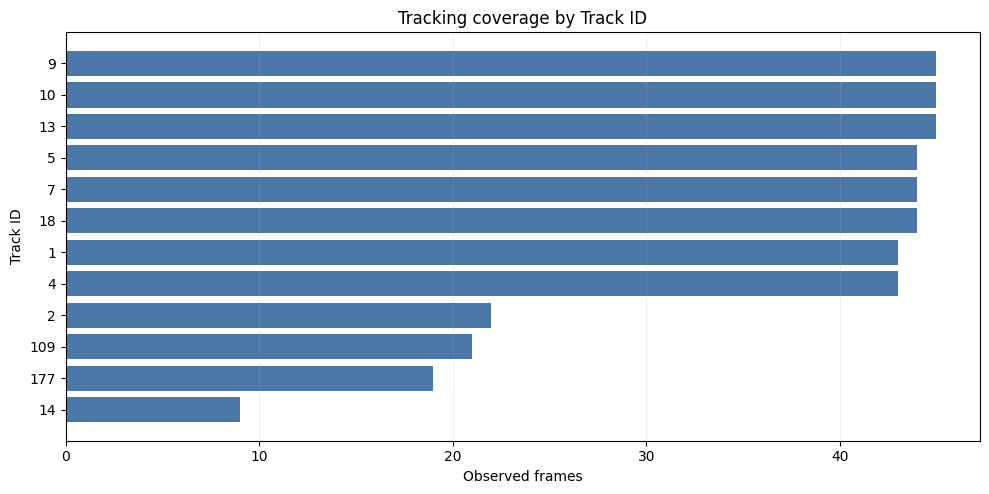

In [5]:
# Export CSV and inspect each Track ID's data volume using a table and chart.
tracks.to_csv(OUT_CSV, index=False)

if tracks.empty:
    summary = pd.DataFrame(columns=["track_id", "frames_seen", "first_frame", "last_frame", "mean_bev_x", "mean_bev_y"])
else:
    summary = (
        tracks.groupby("track_id", dropna=False)
        .agg(
            frames_seen=("frame", "count"),
            first_frame=("frame", "min"),
            last_frame=("frame", "max"),
            mean_bev_x=("bev_x", "mean"),
            mean_bev_y=("bev_y", "mean"),
        )
        .sort_values(["frames_seen", "first_frame"], ascending=[False, True])
        .reset_index()
    )

summary_view = summary.rename(columns={
    "track_id": "Track ID",
    "frames_seen": "Observed frames",
    "first_frame": "First frame",
    "last_frame": "Last frame",
    "mean_bev_x": "Mean BEV X",
    "mean_bev_y": "Mean BEV Y",
}).copy()
if not summary_view.empty:
    summary_view[["Mean BEV X", "Mean BEV Y"]] = summary_view[["Mean BEV X", "Mean BEV Y"]].round(1)

display(Markdown(f"### Track ID Summary\nCSV saved as `{OUT_CSV.name}`. More observed frames indicate that an ID was detected over more of the clip."))
display(summary_view.set_index("Track ID"))

if not summary_view.empty:
    fig, ax = plt.subplots(figsize=(10, max(3, 0.42 * len(summary_view))))
    ax.barh(summary_view["Track ID"].astype(str), summary_view["Observed frames"], color="#4C78A8")
    ax.invert_yaxis()
    ax.set_title("Tracking coverage by Track ID")
    ax.set_xlabel("Observed frames")
    ax.set_ylabel("Track ID")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()


## Step 5 | Add Track-Level Team Clustering

A jersey may be occluded or shadowed in one frame. Collect torso crops of each `track_id` across frames, average its HSV histograms, then cluster tracks into two teams.

```text
tracking records
  -> read source images by frame
  -> crop the torso using each box
  -> encode each crop as an HSV histogram
  -> average features within each track_id
  -> use K-means to form Team A/B
  -> merge team labels into the frame-level table
```

This is more stable than single-frame clustering, but an ID switch can incorrectly mix crops from two players.


### Jersey Sample Collection
Each Track ID uses several torso crops, reducing the influence of shadows or occlusion in an individual frame.

,Crops used,Feature source
Track ID,,
1,6,Mean HSV histogram of multi-frame torso crops
2,3,Mean HSV histogram of multi-frame torso crops
4,6,Mean HSV histogram of multi-frame torso crops
5,6,Mean HSV histogram of multi-frame torso crops
7,6,Mean HSV histogram of multi-frame torso crops
9,6,Mean HSV histogram of multi-frame torso crops
10,6,Mean HSV histogram of multi-frame torso crops
13,6,Mean HSV histogram of multi-frame torso crops
14,2,Mean HSV histogram of multi-frame torso crops


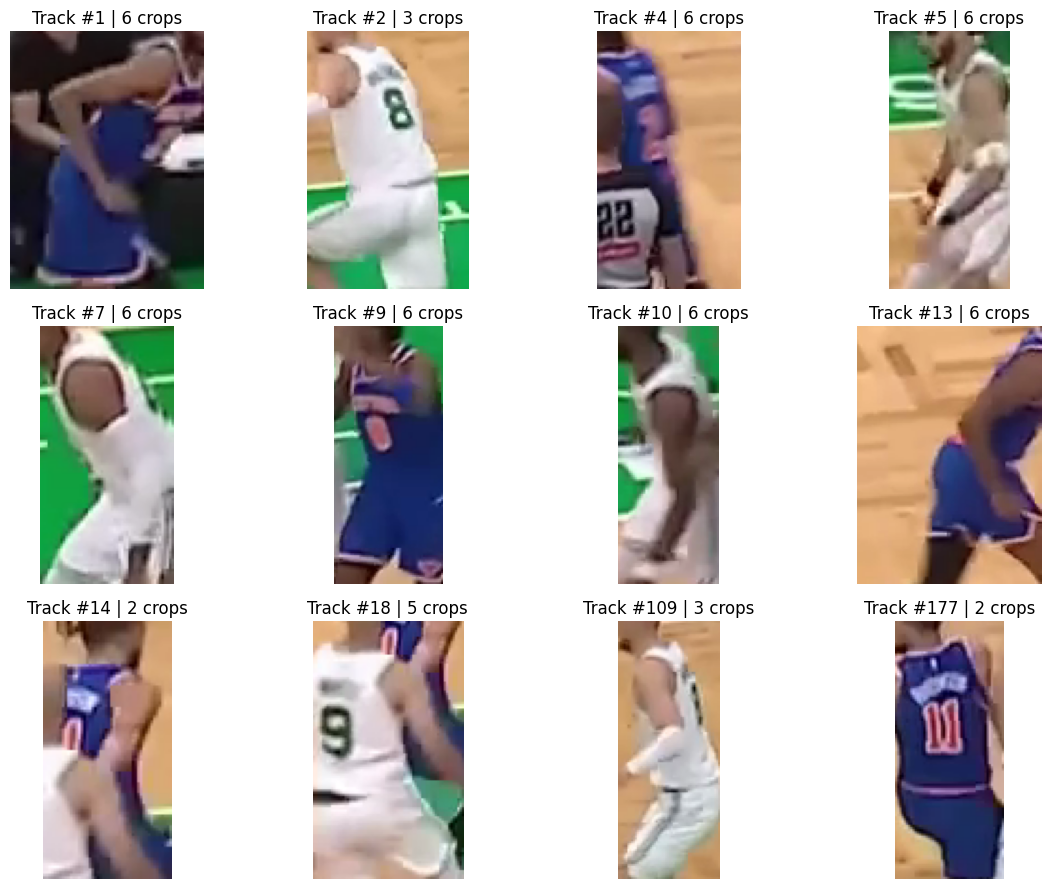

In [6]:
# Collect torso crops and HSV features for each Track ID across frames.
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

from src.cv_utils import save_json
from src.geometry_utils import render_bev_court

TEAM_SAMPLE_STRIDE = 8   # Sample every N frames to reduce near-duplicate crops.
MAX_CROPS_PER_TRACK = 8  # Maximum jersey crops used per track.

def scalar_to_int(value: object) -> int:
    # Convert Pandas/NumPy scalars to Python int and reject non-integer values.
    numeric_value = float(str(value))
    if not numeric_value.is_integer():
        raise ValueError(f"Expected an integer; received {value!r}")
    return int(numeric_value)

def scalar_to_float(value: object) -> float:
    # Convert to text first to exclude complex values from Pandas' broad scalar type.
    return float(str(value))

def bbox_to_floats(value: object) -> tuple[float, float, float, float]:
    # Reject boxes that are not four-element sequences before further processing.
    if not isinstance(value, (list, tuple)) or len(value) != 4:
        raise ValueError(f"Expected four box coordinates; received {value!r}")
    return (
        scalar_to_float(value[0]),
        scalar_to_float(value[1]),
        scalar_to_float(value[2]),
        scalar_to_float(value[3]),
    )

def torso_crop(image, bbox_xyxy):
    # Retain the central upper body to reduce floor, shoe and background contamination.
    image_h, image_w = image.shape[:2]
    x1, y1, x2, y2 = map(float, bbox_xyxy)
    box_w, box_h = x2 - x1, y2 - y1
    crop_x1 = int(np.clip(x1 + 0.20 * box_w, 0, image_w - 1))
    crop_x2 = int(np.clip(x2 - 0.20 * box_w, crop_x1 + 1, image_w))
    crop_y1 = int(np.clip(y1 + 0.10 * box_h, 0, image_h - 1))
    crop_y2 = int(np.clip(y1 + 0.65 * box_h, crop_y1 + 1, image_h))
    return image[crop_y1:crop_y2, crop_x1:crop_x2]

def color_hist_embedding(crop_rgb, hue_bins=12, saturation_bins=8):
    hsv = cv2.cvtColor(np.ascontiguousarray(crop_rgb), cv2.COLOR_RGB2HSV)
    histogram = cv2.calcHist(
        [hsv], [0, 1], None,
        [hue_bins, saturation_bins], [0, 180, 0, 256],
    ).flatten().astype(np.float32)
    return histogram / max(float(np.linalg.norm(histogram)), 1e-12)

# Sample at the specified frame interval and cap crops per track.
candidate_rows = tracks[
    ((tracks["frame"] - START_FRAME) % TEAM_SAMPLE_STRIDE == 0)
    & tracks["track_id"].notna()
].copy()
features_by_track = {}
example_crop_by_track = {}
sampled_rows = []
video = cv2.VideoCapture(str(VIDEO_PATH))
if not video.isOpened():
    raise FileNotFoundError(VIDEO_PATH)

for frame_index, frame_rows in candidate_rows.groupby("frame"):
    frame_number = scalar_to_int(frame_index)
    video.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ok, frame_bgr = video.read()
    if not ok:
        continue
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    for row_index, row in frame_rows.iterrows():
        track_id = scalar_to_int(row["track_id"])
        track_features = features_by_track.setdefault(track_id, [])
        if len(track_features) >= MAX_CROPS_PER_TRACK:
            continue
        crop = torso_crop(frame_rgb, row["bbox_xyxy"])
        if crop.shape[0] < 8 or crop.shape[1] < 8:
            continue
        track_features.append(color_hist_embedding(crop))
        example_crop_by_track.setdefault(track_id, crop)
        sampled_rows.append(row_index)
video.release()

features_by_track = {
    track_id: values for track_id, values in features_by_track.items() if values
}
if len(features_by_track) < 2:
    raise RuntimeError("Fewer than two usable Track IDs. Reduce TEAM_SAMPLE_STRIDE or increase MAX_FRAMES.")

crop_count_table = pd.DataFrame([
    {"Track ID": track_id, "Crops used": len(values), "Feature source": "Mean HSV histogram of multi-frame torso crops"}
    for track_id, values in sorted(features_by_track.items())
])
display(Markdown(
    "### Jersey Sample Collection\n"
    "Each Track ID uses several torso crops, reducing the influence of shadows or occlusion in an individual frame."
))
display(crop_count_table.set_index("Track ID"))

# Inspect crops directly to spot referees, background and crop-placement errors.
preview_track_ids = sorted(example_crop_by_track)[:12]
preview_columns = 4
preview_rows = (len(preview_track_ids) + preview_columns - 1) // preview_columns
fig, axes = plt.subplots(preview_rows, preview_columns, figsize=(12, 3 * preview_rows), squeeze=False)
for axis, track_id in zip(axes.flat, preview_track_ids):
    axis.imshow(example_crop_by_track[track_id])
    axis.set_title(f"Track #{track_id} | {len(features_by_track[track_id])} crops")
    axis.axis("off")
for axis in axes.flat[len(preview_track_ids):]:
    axis.axis("off")
plt.tight_layout()
plt.show()


In [7]:
# Average features within each Track ID, then assign teams with two-cluster K-means.
def kmeans_two_clusters(feature_matrix, max_iterations=50):
    if len(feature_matrix) < 2:
        raise ValueError("K-means requires at least two Track IDs.")
    distances_from_first = np.linalg.norm(feature_matrix - feature_matrix[0], axis=1)
    farthest_index = scalar_to_int(np.argmax(distances_from_first).item())
    centers = feature_matrix[[0, farthest_index]].copy()
    labels = np.full(len(feature_matrix), -1, dtype=int)
    iterations_run = 0
    for iteration in range(max_iterations):
        iterations_run = iteration + 1
        distances = np.linalg.norm(
            feature_matrix[:, None, :] - centers[None, :, :], axis=2
        )
        new_labels = distances.argmin(axis=1)
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels
        for cluster_id in (0, 1):
            members = feature_matrix[labels == cluster_id]
            if len(members):
                centers[cluster_id] = members.mean(axis=0)
    return labels, centers, iterations_run

track_ids = sorted(features_by_track)
track_features = np.vstack([
    np.mean(features_by_track[track_id], axis=0) for track_id in track_ids
])
team_labels, team_centers, team_iterations = kmeans_two_clusters(track_features)
team_by_track = {
    track_id: scalar_to_int(team_label.item())
    for track_id, team_label in zip(track_ids, team_labels)
}
team_names = {0: "Team A", 1: "Team B"}
team_colors = {0: "#00B7FF", 1: "#FF4D6D"}

tracks["team_cluster"] = tracks["track_id"].map(team_by_track)
tracks["team_name"] = tracks["team_cluster"].map(team_names).fillna("Unknown")

TEAM_CSV = COURSE_ROOT / "assets" / "results" / "d3_04_bytetrack_bev_teams.csv"
TEAM_JSON = COURSE_ROOT / "assets" / "results" / "d3_04_bytetrack_bev_teams.json"
tracks.to_csv(TEAM_CSV, index=False)
save_json(tracks.to_dict(orient="records"), TEAM_JSON)

team_summary = (
    tracks.dropna(subset=["team_cluster"])
    .groupby(["team_name", "track_id"])
    .agg(frames_seen=("frame", "count"), mean_confidence=("confidence", "mean"))
    .reset_index()
)
team_summary_view = team_summary.rename(columns={
    "team_name": "Team",
    "track_id": "Track ID",
    "frames_seen": "Observed frames",
    "mean_confidence": "Mean detection confidence",
}).copy()
team_summary_view["Mean detection confidence"] = team_summary_view["Mean detection confidence"].round(3)

team_count_view = (
    team_summary_view.groupby("Team")["Track ID"]
    .nunique()
    .rename("Track ID count")
    .to_frame()
)
output_file_view = pd.DataFrame([
    {"Output": "CSV", "Filename": TEAM_CSV.name, "Use": "Pandas, Excel or statistical analysis"},
    {"Output": "JSON", "Filename": TEAM_JSON.name, "Use": "Programs, web applications or API integration"},
]).set_index("Output")

display(Markdown(
    f"### Team Clustering Results\n"
    f"K-means stopped after **{team_iterations} updates**. Team A/B are cluster names, not actual team identities."
))
display(team_count_view)
display(Markdown("#### Team Assignment and Data Quality by Track ID"))
display(team_summary_view.set_index(["Team", "Track ID"]))
display(Markdown("#### Saved Analysis Files"))
display(output_file_view)


### Team Clustering Results
K-means stopped after **2 updates**. Team A/B are cluster names, not actual team identities.

,Track ID count
Team,
Team A,5
Team B,7


#### Team Assignment and Data Quality by Track ID

Observed frames  Mean detection confidence
Team   Track ID                                            
Team A 1                      43                      0.827
       4                      43                      0.864
       9                      45                      0.931
       13                     45                      0.866
       177                    19                      0.776
Team B 2                      22                      0.860
       5                      44                      0.689
       7                      44                      0.793
       10                     45                      0.860
       14                      9                      0.526
       18                     44                      0.691
       109                    21                      0.777

#### Saved Analysis Files

,Filename,Use
Output,,
CSV,d3_04_bytetrack_bev_teams.csv,"Pandas, Excel or statistical analysis"
JSON,d3_04_bytetrack_bev_teams.json,"Programs, web applications or API integration"


## Step 6 | Export Team Boxes, Feature Plots and BEV Paths

The visualizations address three questions:

1. Which team is each Track ID assigned to in the source frame?
2. Are mean jersey features naturally separated in the 2D PCA view?
3. How are the teams' paths and positions distributed on the BEV court?


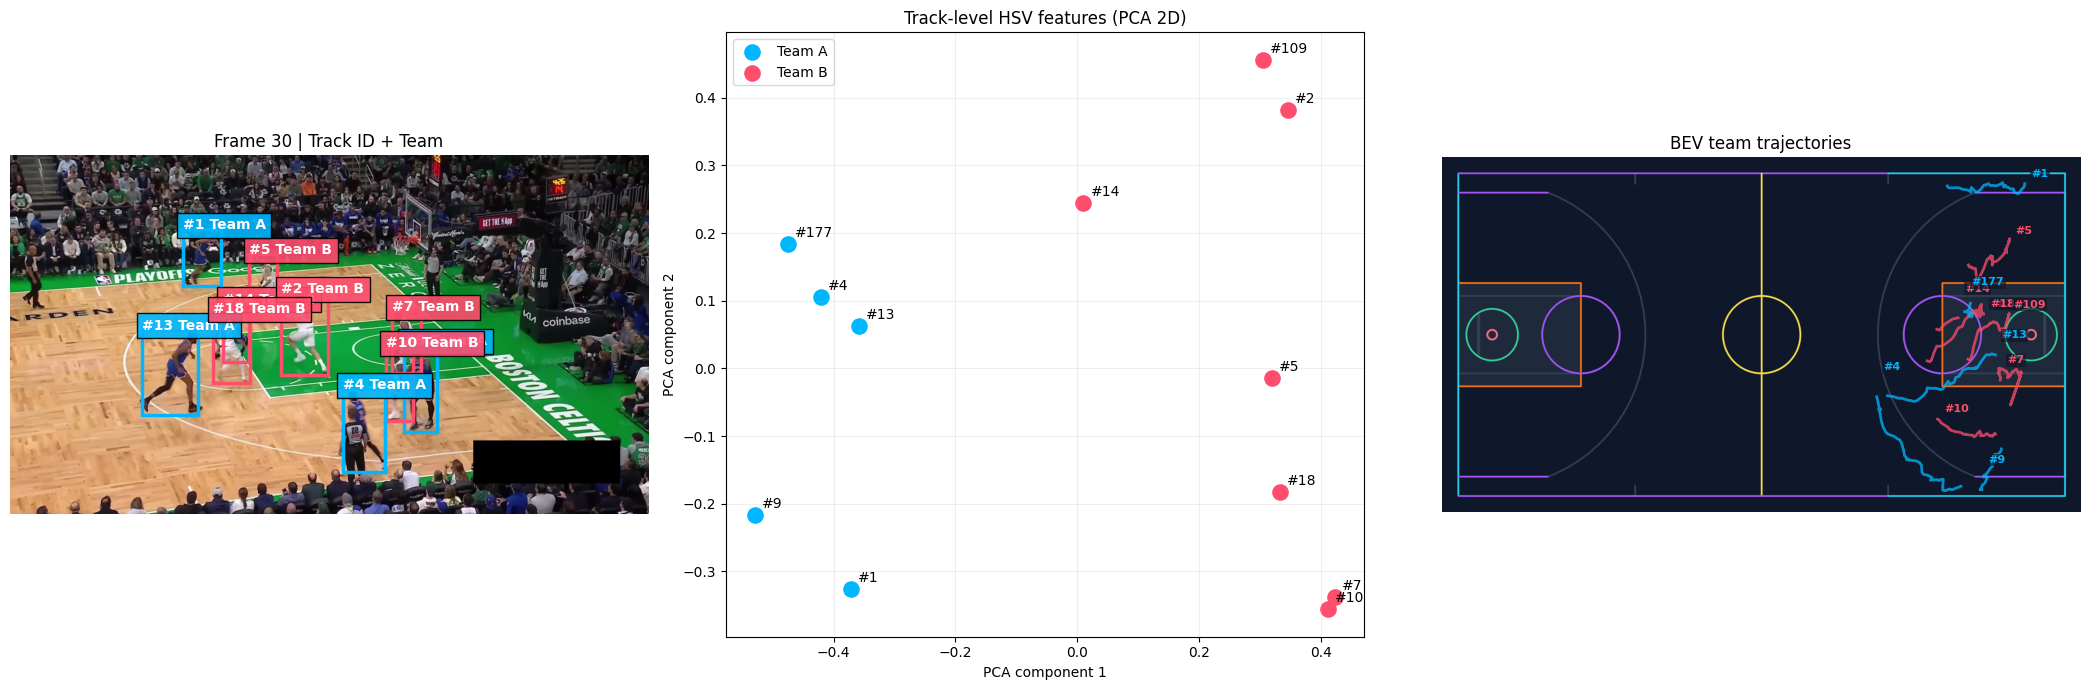

**Reading the figure:** check jersey colors against the left-hand boxes, inspect separation in the middle, then examine team paths on the right.  
Figure saved as `d3_04_team_tracking_visualization.png`.

In [8]:
# Inspect team results in the source frame, feature scatter plot and BEV paths.
sampled_track_rows = tracks.loc[sampled_rows]
visual_frame_index = scalar_to_int(
    sampled_track_rows.groupby("frame").size().idxmax()
)
video = cv2.VideoCapture(str(VIDEO_PATH))
video.set(cv2.CAP_PROP_POS_FRAMES, visual_frame_index)
ok, visual_frame_bgr = video.read()
video.release()
if not ok:
    raise RuntimeError(f"Cannot read the representative frame: {visual_frame_index}")
visual_frame = cv2.cvtColor(visual_frame_bgr, cv2.COLOR_BGR2RGB)

# PCA is for the 2D plot only; K-means uses full HSV features.
centered_features = track_features - track_features.mean(axis=0, keepdims=True)
_, _, vh = np.linalg.svd(centered_features, full_matrices=False)
component_count = min(2, vh.shape[0])
feature_2d = centered_features @ vh[:component_count].T
if component_count == 1:
    feature_2d = np.column_stack([feature_2d[:, 0], np.zeros(len(feature_2d))])

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# Left: Track IDs and team-colored boxes in the representative frame.
axes[0].imshow(visual_frame)
axes[0].set_title(f"Frame {visual_frame_index} | Track ID + Team")
axes[0].axis("off")
for _, row in tracks[tracks["frame"] == visual_frame_index].iterrows():
    row_track_id = scalar_to_int(row["track_id"])
    cluster_id = team_by_track.get(row_track_id)
    if cluster_id is None:
        continue
    x1, y1, x2, y2 = row["bbox_xyxy"]
    color = team_colors[cluster_id]
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=color, linewidth=2.5))
    axes[0].text(x1, y1, f"#{row_track_id} {team_names[cluster_id]}",
                 color="white", weight="bold",
                 bbox={"facecolor": color, "alpha": 0.9})

# Middle: one point per Track ID's mean jersey feature.
for cluster_id in (0, 1):
    mask = team_labels == cluster_id
    axes[1].scatter(feature_2d[mask, 0], feature_2d[mask, 1], s=120,
                    color=team_colors[cluster_id], label=team_names[cluster_id])
for index, track_id in enumerate(track_ids):
    axes[1].annotate(f"#{track_id}", feature_2d[index], xytext=(5, 5),
                     textcoords="offset points")
axes[1].set_title("Track-level HSV features (PCA 2D)")
axes[1].set_xlabel("PCA component 1")
axes[1].set_ylabel("PCA component 2")
axes[1].legend()
axes[1].grid(alpha=0.2)

# Right: shared team colors, with a separate BEV path for each Track ID.
bev_image = render_bev_court(BEV_SPEC_PATH)
axes[2].imshow(bev_image)
for path_index, (track_id, path_rows) in enumerate(
    tracks.dropna(subset=["team_cluster"]).groupby("track_id")
):
    cluster_id = scalar_to_int(path_rows["team_cluster"].iloc[0])
    path_track_id = scalar_to_int(track_id)
    ordered = path_rows.sort_values("frame")
    axes[2].plot(ordered["bev_x"], ordered["bev_y"],
                 color=team_colors[cluster_id], linewidth=2, alpha=0.75)
    axes[2].annotate(
        f"#{path_track_id}",
        (ordered["bev_x"].iloc[-1], ordered["bev_y"].iloc[-1]),
        xytext=(5, 5 + (path_index % 3) * 7),
        textcoords="offset points",
        color=team_colors[cluster_id],
        fontsize=8,
        weight="bold",
        bbox={"facecolor": "#101827", "edgecolor": "none", "alpha": 0.65, "pad": 1},
    )
axes[2].set_title("BEV team trajectories")
axes[2].axis("off")

TEAM_VIS_PATH = COURSE_ROOT / "assets" / "results" / "d3_04_team_tracking_visualization.png"
plt.tight_layout()
fig.savefig(TEAM_VIS_PATH, dpi=160, bbox_inches="tight")
plt.show()
display(Markdown(
    f"**Reading the figure:** check jersey colors against the left-hand boxes, inspect separation in the middle, then examine team paths on the right.  \n"
    f"Figure saved as `{TEAM_VIS_PATH.name}`."
))


## Step 7 | Export Team Tracking Video

A static image checks one instant. Video reveals whether team labels remain stable with Track IDs. The side-by-side output contains:

- **Left, camera view**: team-colored player boxes labeled with `Track ID + Team`.
- **Right, BEV view**: paths for individual Track IDs, sharing a color within each team.

A label jumping from one player to another usually indicates an ID switch, rather than a sudden change in the clustering decision.


In [9]:
# Draw team boxes and BEV paths frame by frame, then export a playable MP4.
from contextlib import redirect_stdout
from io import StringIO

TEAM_VIDEO_PATH = COURSE_ROOT / "assets" / "results" / "d3_04_bytetrack_bev_teams.mp4"
PANEL_WIDTH = 960
PANEL_HEIGHT = 540

def hex_to_bgr(hex_color):
    # Matplotlib uses RGB hex colors; OpenCV requires BGR tuples.
    value = hex_color.lstrip("#")
    red, green, blue = (int(value[index:index + 2], 16) for index in (0, 2, 4))
    return blue, green, red

team_colors_bgr = {
    cluster_id: hex_to_bgr(color) for cluster_id, color in team_colors.items()
}
rows_by_frame = {
    scalar_to_int(frame_key): frame_rows
    for frame_key, frame_rows in tracks.groupby("frame")
}
trail_history = {track_id: [] for track_id in team_by_track}

source_video = cv2.VideoCapture(str(VIDEO_PATH))
if not source_video.isOpened():
    raise FileNotFoundError(VIDEO_PATH)
source_fps = source_video.get(cv2.CAP_PROP_FPS) or 30.0
source_video.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME)

writer = cv2.VideoWriter(
    str(TEAM_VIDEO_PATH),
    cv2.VideoWriter.fourcc("m", "p", "4", "v"),
    source_fps,
    (PANEL_WIDTH * 2, PANEL_HEIGHT),
)
if not writer.isOpened():
    source_video.release()
    raise RuntimeError(f"Cannot create output video: {TEAM_VIDEO_PATH}")

bev_base_rgb = render_bev_court(BEV_SPEC_PATH)
bev_base_bgr = cv2.cvtColor(bev_base_rgb, cv2.COLOR_RGB2BGR)
bev_source_h, bev_source_w = bev_base_bgr.shape[:2]
bev_scale_x = PANEL_WIDTH / bev_source_w
bev_scale_y = PANEL_HEIGHT / bev_source_h

written_frames = 0
for frame_number in range(START_FRAME, START_FRAME + MAX_FRAMES):
    ok, frame_bgr = source_video.read()
    if not ok:
        break

    source_h, source_w = frame_bgr.shape[:2]
    camera_panel = cv2.resize(frame_bgr, (PANEL_WIDTH, PANEL_HEIGHT))
    camera_scale_x = PANEL_WIDTH / source_w
    camera_scale_y = PANEL_HEIGHT / source_h
    bev_panel = cv2.resize(bev_base_bgr, (PANEL_WIDTH, PANEL_HEIGHT))
    frame_rows = rows_by_frame.get(frame_number)

    if frame_rows is not None:
        for row in frame_rows.itertuples(index=False):
            track_id = scalar_to_int(row.track_id)
            cluster_id = team_by_track.get(track_id)
            if cluster_id is None:
                continue
            color = team_colors_bgr[cluster_id]
            x1, y1, x2, y2 = bbox_to_floats(row.bbox_xyxy)
            box_start = (round(x1 * camera_scale_x), round(y1 * camera_scale_y))
            box_end = (round(x2 * camera_scale_x), round(y2 * camera_scale_y))
            cv2.rectangle(camera_panel, box_start, box_end, color, 3)

            label = f"#{track_id} {team_names[cluster_id]}"
            (label_w, label_h), _ = cv2.getTextSize(
                label, cv2.FONT_HERSHEY_SIMPLEX, 0.6, 2
            )
            label_top = max(0, box_start[1] - label_h - 10)
            cv2.rectangle(
                camera_panel,
                (box_start[0], label_top),
                (box_start[0] + label_w + 10, label_top + label_h + 10),
                color,
                -1,
            )
            cv2.putText(
                camera_panel, label, (box_start[0] + 5, label_top + label_h + 4),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA,
            )

            bev_point = (
                round(scalar_to_float(row.bev_x) * bev_scale_x),
                round(scalar_to_float(row.bev_y) * bev_scale_y),
            )
            trail_history[track_id].append(bev_point)

    # Redraw accumulated paths in each frame to show each player's movement.
    for track_id, points in trail_history.items():
        if not points:
            continue
        cluster_id = team_by_track[track_id]
        color = team_colors_bgr[cluster_id]
        if len(points) >= 2:
            cv2.polylines(
                bev_panel, [np.asarray(points, dtype=np.int32)], False,
                color, 3, cv2.LINE_AA,
            )
        cv2.circle(bev_panel, points[-1], 7, color, -1, cv2.LINE_AA)
        cv2.putText(
            bev_panel, f"#{track_id}", (points[-1][0] + 8, points[-1][1] - 8),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2, cv2.LINE_AA,
        )

    cv2.putText(camera_panel, "Camera view | Track ID + Team", (20, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 2, cv2.LINE_AA)
    cv2.putText(bev_panel, "BEV | Team-colored trajectories", (20, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(np.hstack([camera_panel, bev_panel]))
    written_frames += 1

source_video.release()
writer.release()
if written_frames == 0:
    raise RuntimeError("No frames were written to the team tracking video.")

# Convert mp4v to H.264/yuv420p for browser playback before embedding.
with redirect_stdout(StringIO()):
    ensure_notebook_playable_mp4(TEAM_VIDEO_PATH)
video_summary = pd.DataFrame([
    {"Video info": "Layout", "Result": "Left: camera team boxes | Right: BEV team paths"},
    {"Video info": "Resolution", "Result": f"{PANEL_WIDTH * 2} x {PANEL_HEIGHT}"},
    {"Video info": "Frames", "Result": written_frames},
    {"Video info": "Duration", "Result": f"{written_frames / source_fps:.2f} s"},
    {"Video info": "Browser codec", "Result": "H.264 / yuv420p"},
    {"Video info": "Output filename", "Result": TEAM_VIDEO_PATH.name},
]).set_index("Video info")

display(Markdown(
    "### Team Tracking Video Saved\n"
    "🟦 **Team A**　🟥 **Team B**. Check that each Track ID keeps its color throughout playback."
))
display(video_summary)
display_video_in_notebook(TEAM_VIDEO_PATH, loop=True)


### Team Tracking Video Saved
🟦 **Team A**　🟥 **Team B**. Check that each Track ID keeps its color throughout playback.

,Result
Video info,
Layout,Left: camera team boxes | Right: BEV team paths
Resolution,1920 x 540
Frames,45
Duration,1.50 s
Browser codec,H.264 / yuv420p
Output filename,d3_04_bytetrack_bev_teams.mp4


## Mini Project Checks and Limitations

### Outputs

- `assets/results/d3_04_bytetrack_bev.mp4`: side-by-side camera/BEV tracking video.
- `assets/results/d3_04_bytetrack_bev.json`: original tracking-to-BEV records.
- `assets/results/d3_04_bytetrack_bev.csv`: frame-level table before team assignments.
- `assets/results/d3_04_bytetrack_bev_teams.csv` / `.json`: records with Team A/B.
- `assets/results/d3_04_team_tracking_visualization.png`: team boxes, feature scatter plot and team-colored BEV paths.
- `assets/results/d3_04_bytetrack_bev_teams.mp4`: side-by-side team tracking and BEV paths.

### Interpretation Limits

- Homography error shifts BEV positions without necessarily changing Track IDs or team labels.
- An ID switch mixes different players' jersey features and paths.
- Team A/B are unlabeled cluster names, not actual teams; assignments may swap after rerunning or changing data.
- Referees, similar jerseys, shadows and severe occlusion can still cause errors. A full project should consider referee exclusion, manual correction or image embeddings.
